In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
def run_clustering(dist, minsize, outfile=None):
    clusterer = HDBSCAN(metric="precomputed", min_cluster_size=minsize, copy=False)
    labels = clusterer.fit_predict(dist)
    print("HDBSCAN labels:", labels)
    if outfile:
        np.save(outfile, labels)
    return labels


In [3]:
import sys
import os
import pandas as pd
import MDAnalysis as mda
import re
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import HDBSCAN

sys.path.append("/scratch/mgilioli/vis/scripts/")
from helper import read_ipf_alt

TOPOLOGY = "/scratch/mgilioli/PHD_Maurizio_BussiLab/simulations_and_analysis/12-3-analyze_interactions/reduced_traj_interface_int/topol_interface.pdb"
TRAJECTORY = "/scratch/mgilioli/PHD_Maurizio_BussiLab/simulations_and_analysis/12-3-analyze_interactions/reduced_traj_interface_int/traj_interface.xtc"
# %TODO i want the script to be able to work even if the user provides only a directory of pdbs, given that the topology is valid for all of them
# dirframes
INTERACTION_FILE = "/scratch/mgilioli/PHD_Maurizio_BussiLab/simulations_and_analysis/12-3-analyze_interactions/rna_interface_contacts/rna_interface_contacts.csv"
GROUP_DISTANCE = 10.0  # Angstrom; smaller -> more, smaller groups
STARTING_FRAME = True
THRESHOLD=0.1

# check presence of files
if not os.path.exists(INTERACTION_FILE):
    raise Exception(f"{INTERACTION_FILE} does not exist unfortunately")

# read the interaction file
# one row per frame, one (RNA, protein) column per residue pair: 1 if any interaction
df = read_ipf_alt(INTERACTION_FILE)
u = mda.Universe(TOPOLOGY, TRAJECTORY)

# Keep columns with significant information
frequency = df.apply(
    lambda col: col.map(
        lambda x: bool(x) if isinstance(x, list)
        else bool(x) if pd.notna(x)
        else False
    ).mean()
)
keep = frequency.between(THRESHOLD, 1 - THRESHOLD)
print(f"{len(df.columns)}", end=" ")
df = df.loc[:, keep]
print(f"-> {len(df.columns)}")

122 -> 64


In [4]:
def get_residue(label):
    """Label like 'C10.C' or 'ARG152.I' -> MDAnalysis Residue."""
    if label in label_to_residue:
        return label_to_residue[label]
    resname, resid, chain = re.fullmatch(r"([A-Za-z]+)(\d+)\.(\w+)", label).groups()
    sel = u.select_atoms(f"chainID {chain} and resname {resname} and resid {resid}")
    if len(sel.residues) != 1:
        raise ValueError(f"Label {label} matches {len(sel.residues)} residues")
    return sel.residues[0]

def residue_label(residue):
    """Residue -> label in the interaction-file format, e.g. 'ARG152.I'."""
    return f"{residue.resname}{residue.resid}.{residue.atoms.chainIDs[0]}"



In [5]:
from MDAnalysis.lib.distances import distance_array

def residue_label(residue):
    """Residue -> label in the interaction-file format, e.g. 'ARG152.I'."""
    return f"{residue.resname}{residue.resid}.{residue.atoms.chainIDs[0]}"

label_to_residue = {residue_label(res): res for res in u.residues}

if len(u.trajectory) != len(df):
    raise ValueError(
        f"Trajectory has {len(u.trajectory)} frames, but df has {len(df)} rows"
    )

interactions = list(df.columns)
atom_pairs = [
    (get_residue(el1).atoms, get_residue(el2).atoms)
    for el1, el2 in interactions
]

distances = np.empty((len(df), len(interactions)), dtype=float)

for frame_idx, ts in enumerate(u.trajectory):
    for interaction_idx, (atoms_a, atoms_b) in enumerate(atom_pairs):
        pair_distances = distance_array(
            atoms_a.positions,
            atoms_b.positions,
            box=ts.dimensions,
        )
        distances[frame_idx, interaction_idx] = pair_distances.min()

df_dist = pd.DataFrame(distances, index=df.index, columns=df.columns)


In [6]:
# Verify that list have all the same length
columns = df.columns
# Use .map() instead of applymap()
lengths = df.map(lambda x: len(x) if isinstance(x, list) else None)
# Check if all lengths are the same (include dropna=False if None matters)
consistent_lengths = lengths.apply(lambda col: col.nunique(dropna=False) == 1)
# Print the result as a Series
if any(consistent_lengths == False): raise Exception("The list have not always same length")

In [7]:

# Map every label in the universe to its MDAnalysis Residue
label_to_residue = {residue_label(res): res for res in u.residues}

# Group interactions by where they are in space.
interactions = list(columns)
atom_pairs = [(get_residue(a).atoms, get_residue(b).atoms) for a, b in interactions]
positions = np.zeros((len(interactions), 3))
# Use only the starting frame to define the groups
if STARTING_FRAME:
    u.trajectory[0] # Set to first frame
    positions += [(a.center_of_geometry() + b.center_of_geometry()) / 2 for a, b in atom_pairs]
# Use all the frames to define the groups
else:
    for ts in u.trajectory:
        positions += [(a.center_of_geometry() + b.center_of_geometry()) / 2 for a, b in atom_pairs]
    positions /= len(u.trajectory)

# pdist generates a condensed 1D array of distances, linkage clusters together the elements iteratively, fcluster cuts the hierarchical clustering at a certain distance 
group_ids = fcluster(linkage(pdist(positions), method="average"), GROUP_DISTANCE, criterion="distance")

# interaction_groups: list of lists of interactions
# residue_groups: list of sorted residue labels involved in each group
interaction_groups = [
    [inter for inter, gid in zip(interactions, group_ids) if gid == k] for k in sorted(set(group_ids))
]
residue_groups = [sorted({res for inter in group for res in inter}) for group in interaction_groups]
for i, group in enumerate(interaction_groups):
    print(f"group {i}: {len(group)} interactions")

group 0: 7 interactions
group 1: 11 interactions
group 2: 1 interactions
group 3: 2 interactions
group 4: 3 interactions
group 5: 8 interactions
group 6: 10 interactions
group 7: 13 interactions
group 8: 9 interactions


In [8]:
import matplotlib.pyplot as plt

HDBSCAN labels: [-1 30 25 30 31 31 31 31 31 31 29 -1 -1 11 14 11 11 14 14 14 -1 -1 29 20
 32 32 -1 33 -1 33 20  1  1  1  1  1  1  0  0  0  1  3  4  6  3  4  4  3
  4  3  6 -1 21 21 16 16 22 22 -1 21 21 -1 24 24 24 24 24 24 24 24 24  6
  6  6  6  6  6  5  6  5  6 34 34 35 35 26 34 26 35 34 34 -1 23 23 -1 -1
 23 -1 -1 15 15  7  8 10  8  8  8  1 10 -1  8 -1 25 19 -1  7 -1  9 19 19
 19  9 27 25 28 19 28 28 19 27 28 25 12 12 12 13 13 12 13 12 12 13  2  2
  6  2  2  2  6  2  3  2 18 18 18 17 18 17 -1 17 17 18]


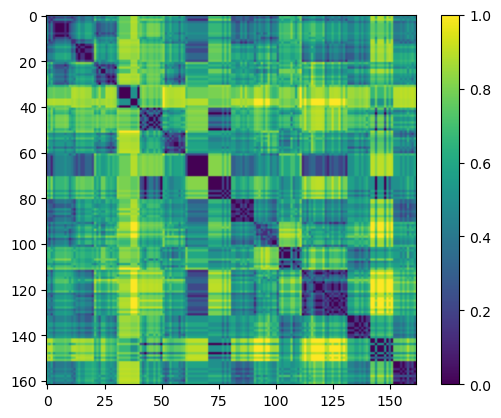

In [17]:

coords = df[interaction_groups[7]].to_numpy().astype(bool)

# Jaccard: fraction of differing contacts among those present in either frame,
# so contacts absent in both frames don't count as similarity
dist_matrix = squareform(pdist(coords, metric="jaccard"))

MINSIZE=2
labels = run_clustering(dist_matrix, MINSIZE)

plt.imshow(dist_matrix)
plt.colorbar()


In [18]:
def compute_mds_coords(dist, random_state=0, n_jobs=-1):
    """MDS layout of a precomputed distance matrix -- the expensive part of
    plot_cluster_network (n_init=4 restarts over the full n_frames x
    n_frames matrix takes tens of minutes at ~5000 frames). Factored out so
    callers that need the same `dist` laid out for several plots (e.g. one
    figure's model/HDBSCAN/KMeans panels, or many configs sharing one sweep's
    distance matrix) can compute it once and reuse it, instead of every
    plot_cluster_network call silently redoing an identical fit.

    n_jobs=-1 runs the n_init restarts in parallel (they're independent SMACOF
    fits from different random inits) rather than sequentially -- match the
    caller's job to however many CPUs are actually requested for it.
    """
    from sklearn.manifold import MDS

    return MDS(
        n_components=2, metric="precomputed", normalized_stress=False,
        init="random", n_init=4, random_state=random_state, n_jobs=n_jobs,
    ).fit_transform(dist)



In [19]:
def plot_cluster_network(dist, labels, outfile=None, ax=None,
                          title="Frame clustering (MDS layout, MST backbone)", coords=None,
                          label_prefix="cluster"):
    """Visualize a precomputed distance matrix as a network, colored by
    cluster label, to eyeball whether the clustering makes sense.

    Points (frames) are laid out with MDS on `dist` itself, so on-screen
    distance reflects actual pairwise distance rather than an arbitrary
    graph layout -- points HDBSCAN put in the same cluster should visibly
    sit together. The minimum spanning tree of `dist` is drawn underneath
    as light edges (the same "nearest neighbor" backbone structure HDBSCAN's
    own linkage is built from) to show how clusters connect to each other
    and to noise.

    `labels` is the array returned by `run_clustering` (or
    `HDBSCAN(...).fit_predict(dist)` directly); noise points (label -1)
    are drawn in gray.

    `coords` lets a caller reuse an MDS layout already computed for this
    same `dist` (via compute_mds_coords) instead of recomputing it here --
    the layout only depends on `dist`, not on `labels`, so plotting several
    label sets (or several clustering configs) against one distance matrix
    should fit MDS once, not once per plot.

    `label_prefix` names the legend entries for non-noise labels (default
    "cluster", e.g. "cluster 0") -- pass "model" when `labels` is a source-
    model assignment rather than a clustering result, so the legend reads
    "model 0", "model 1", ... instead of implying a cluster that isn't one.
    """
    from scipy.sparse.csgraph import minimum_spanning_tree
    import matplotlib.pyplot as plt

    if coords is None:
        coords = compute_mds_coords(dist)

    mst = minimum_spanning_tree(dist).tocoo()

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))

    for i, j in zip(mst.row, mst.col):
        ax.plot(coords[[i, j], 0], coords[[i, j], 1], color="lightgray", linewidth=0.5, zorder=1)

    cmap = plt.get_cmap("tab10")
    for k, label in enumerate(sorted(set(labels))):
        mask = labels == label
        if label == -1:
            color, name = "lightgray", "noise"
        else:
            color, name = cmap(k % 10), f"{label_prefix} {label}"
        ax.scatter(coords[mask, 0], coords[mask, 1], s=15, color=color, label=name, zorder=2)

    ax.legend(markerscale=2, fontsize=8)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

    if outfile:
        plt.savefig(outfile, dpi=150, bbox_inches="tight")
    return ax


<Axes: title={'center': 'prova'}>

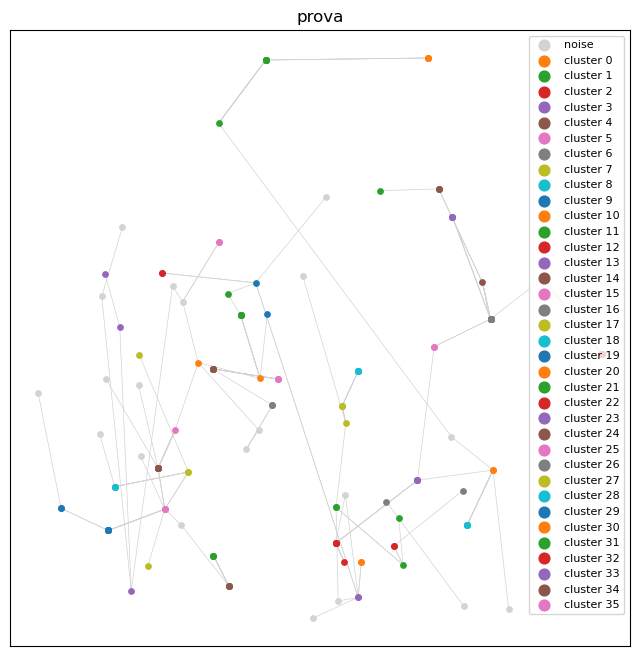

In [20]:
plot_cluster_network(dist_matrix, labels=labels, outfile="canc.png", title="prova")

In [46]:
dist_matrix

array([[0. , 0. , 0. , ..., 0.5, 0.5, 0.5],
       [0. , 0. , 0. , ..., 0.5, 0.5, 0.5],
       [0. , 0. , 0. , ..., 0.5, 0.5, 0.5],
       ...,
       [0.5, 0.5, 0.5, ..., 0. , 0. , 0. ],
       [0.5, 0.5, 0.5, ..., 0. , 0. , 0. ],
       [0.5, 0.5, 0.5, ..., 0. , 0. , 0. ]], shape=(162, 162))

In [40]:
run_clustering(dist=dist_matrix, minsize=2)

HDBSCAN labels: [ 1  2  2  2  2  2  2  2  2  2  2  6  6  6 -1  6  6  5  5  3  3  2  2  2
  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2
  2  2  2  2  4  2  2  2  2  2  0  2  2  2  2  2  2  2  2  4  2  2  2  2
  2  2  2  2  2  2  4  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2
  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2
  2  2  3  5  5  5  5  5  5  5  5  5  2  2  0  2  2  2  0  0  2  2  4  4
  0  2  2  2  4  0  2  1  2  1  2  2  2  2  4  2  2  2]


array([ 1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  6,  6,  6, -1,  6,  6,
        5,  5,  3,  3,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  4,  2,  2,  2,  2,  2,  0,  2,  2,  2,  2,  2,  2,  2,  2,  4,
        2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  4,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  3,  5,  5,  5,  5,  5,  5,  5,  5,  5,  2,  2,  0,  2,
        2,  2,  0,  0,  2,  2,  4,  4,  0,  2,  2,  2,  4,  0,  2,  1,  2,
        1,  2,  2,  2,  2,  4,  2,  2,  2])

In [ ]:
OUTDIR="/scratch/mgilioli/vis/prova"

In [ ]:
MINSIZE=2
NCLUSTERS=3

In [11]:
import json

In [ ]:
os.makedirs(OUTDIR, exist_ok=True)
hdbscan_labels_out = os.path.join(OUTDIR, "labels_hdbscan.npy")
kmeans_labels_out = os.path.join(OUTDIR, "labels_kmeans.npy")
metrics_out = os.path.join(OUTDIR, "metrics.json")

hdbscan_labels = run_clustering(dist, MINSIZE, outfile=hdbscan_labels_out)
print(f"Wrote HDBSCAN cluster labels to {hdbscan_labels_out}")
# kmeans_labels = run_kmeans_clustering(dist, NCLUSTERS, outfile=kmeans_labels_out)
# print(f"Wrote KMeans cluster labels to {kmeans_labels_out}")

hdbscan_silhouette = evaluate_clustering(dist, hdbscan_labels)
# kmeans_silhouette = evaluate_clustering(dist, kmeans_labels)
with open(metrics_out, "w") as f:
    json.dump(
        # {"hdbscan_silhouette": hdbscan_silhouette, "kmeans_silhouette": kmeans_silhouette},
        {"hdbscan_silhouette": hdbscan_silhouette},
        f, indent=2,
    )
print(f"Wrote silhouette scores to {metrics_out}")

